# Low-default portfolios: the most prudent estimate of Pluto and Tasche

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 02 of this topic (intervals on a thin grade)
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- explain the most prudent estimate: a PD for each grade as an upper confidence bound, under the assumption that every worse grade has the same PD, and say why it needs pooled counts;
- compute the bound for independent defaults and check it against the closed form for zero defaults and against SciPy's Beta quantile;
- add default correlation with the one-factor model, and read how much the bound rises;
- scale the bounds to a portfolio target, and carry a multi-year cohort with serially correlated factors;
- recompute the 204 printed cells of Pluto and Tasche's Tables 1 to 14, list the cells that deviate and say why;
- read what the committed known-truth study says about coverage, and what the bounds cost in capital.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.engines import low_default as ld
from riskvalidation.regulatory import capital_requirement
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Four committed files of case C05, the second half of the case: low-default portfolios (licence class `derived-only` for the printed tables of Pluto and Tasche, 2005; https://arxiv.org/abs/cond-mat/0411699):

- `data/derived/C05/ldp-published.json`: the example of the paper, three grades A, B and C with 100, 400 and 300 obligors and 0, 2 and 1 defaults, the bounds at six confidence levels, the 204 printed cells of Tables 1 to 14 with the recomputation (`outputs.golden`), the committed tests of a hypothetical expert's PDs, and the capital impact.
- `data/derived/C05/ldp-sim-0.json`, `ldp-sim-1.json` and `ldp-sim-3.json`: the same portfolio in a year generated by a Vasicek model with known PDs (0.05%, 0.10% and 0.20%, correlation 12%) with no default, one and three, each with the coverage of the bounds and the size and power of the tests measured over 20,000 generated years.

The grade counts here are the paper's own example, public in the paper. The next cell loads the files and prints what they hold.

In [2]:
# Load the four artifacts (the notebook sits three folders below the repository root) and print the example
ROOT = Path("../../..").resolve()
C05 = ROOT / "data" / "derived" / "C05"
load = lambda name: json.loads((C05 / name).read_text(encoding="utf-8"))
published = load("ldp-published.json")
sims = {k: load(f"ldp-sim-{k}.json") for k in (0, 1, 3)}
out = published["outputs"]
grades, N, few = out["grades"], tuple(out["obligors"]), tuple(out["defaults"])
gammas, rho = out["gammas"], out["rho"]

for label, doc in [("ldp-published", published)] + [(f"ldp-sim-{k}", d) for k, d in sims.items()]:
    print(f"{label:14s} baked by riskvalidation", doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print("grades:", grades, "| obligors:", N, "| defaults:", few)
print("confidence levels:", gammas, "| asset correlation of the paper:", rho)
print("hypothetical expert PDs:", out["expert_pd"])

ldp-published  baked by riskvalidation 0.4.3 | installed 0.8.1
ldp-sim-0      baked by riskvalidation 0.4.3 | installed 0.8.1
ldp-sim-1      baked by riskvalidation 0.4.3 | installed 0.8.1
ldp-sim-3      baked by riskvalidation 0.4.3 | installed 0.8.1
grades: ['A', 'B', 'C'] | obligors: (100, 400, 300) | defaults: (0, 2, 1)
confidence levels: [0.5, 0.75, 0.9, 0.95, 0.99, 0.999] | asset correlation of the paper: 0.12
hypothetical expert PDs: [0.0003, 0.0005, 0.001]


## Method

### Step 1: the most prudent estimate, independent defaults

With three defaults in 800 obligors a portfolio has a default rate, but the individual grades do not: A has none. Pluto and Tasche (2005) ask for the PD of each grade as an **upper confidence bound** at level $\gamma$, under the *most prudent* assumption compatible with the ordering of the grades: every grade from $i$ downward has the same PD, so the obligors and the defaults of grades $i, \dots, k$ are pooled. With $N$ pooled obligors and $D$ pooled defaults, independent defaults, the bound $p$ solves

$$P\bigl(\mathrm{Binomial}(N, p) \le D\bigr) = 1 - \gamma$$

(the Clopper-Pearson upper bound). For $D = 0$ it has the closed form $p = 1 - (1 - \gamma)^{1/N}$. The engine's `most_prudent_pd` returns the bounds and the pooled counts. Two independent checks apply: the closed form for a case with no default, and the Beta distribution quantile of SciPy, since the binomial tail and the Beta distribution function are the same function. The cell prints the pooled counts, the bounds at 90%, the checks and the comparison with the committed bounds.

In [3]:
# The most prudent bounds of the example at 90%, the closed form for zero defaults, SciPy's Beta quantile, and the committed bounds
gamma = 0.9
r = ld.most_prudent_pd(N, few, gamma)
print("pooled obligors (grade i down to the worst):", r["pooled_obligors"], "| pooled defaults:", r["pooled_defaults"])
beta_check = [stats.beta.ppf(gamma, d + 1, n - d) for n, d in zip(r["pooled_obligors"], r["pooled_defaults"])]
print(f"{'grade':8s}{'bound at 90% (%)':>26s}{'Beta quantile (%)':>26s}")
for g, p, b in zip(grades, r["pd"], beta_check):
    print(f"{g:8s}{100 * p:26.4f}{100 * b:26.4f}")
print("equal to the Beta quantile:", bool(np.allclose(r["pd"], beta_check, atol=1e-12)))

zero = ld.most_prudent_pd(N, (0, 0, 0), gamma)
closed = [1 - (1 - gamma) ** (1 / n) for n in zero["pooled_obligors"]]
print("zero defaults: engine", [round(100 * p, 4) for p in zero["pd"]], "| closed form", [round(100 * p, 4) for p in closed], "| equal:", bool(np.allclose(zero["pd"], closed, atol=1e-12)))
committed = np.array(out["bounds"]["independent"])
print("equal to the committed bounds, six levels:", bool(np.allclose([ld.most_prudent_pd(N, few, g)["pd"] for g in gammas], committed, atol=1e-9)))

pooled obligors (grade i down to the worst): [800, 700, 300] | pooled defaults: [3, 3, 1]
grade             bound at 90% (%)         Beta quantile (%)
A                           0.8332                    0.8332
B                           0.9519                    0.9519
C                           1.2903                    1.2903
equal to the Beta quantile: True
zero defaults: engine [0.2874, 0.3284, 0.7646] | closed form [0.2874, 0.3284, 0.7646] | equal: True
equal to the committed bounds, six levels: True


The bounds rise from A to C, as the construction guarantees, and every grade, even A with no default, gets a positive PD that rests on all 800 obligors. The cost is conservatism: the bounds say how high the PD can be at that confidence, not what it probably is.

### Step 2: default correlation

Defaults of obligors that share an economy are correlated, and the binomial law then understates the spread of the number of defaults. Pluto and Tasche (section 4) use the one-factor model: each obligor defaults when $\sqrt{\rho}\,Y + \sqrt{1-\rho}\,\xi$ falls below $\Phi^{-1}(p)$, with a common factor $Y$, so given $Y = y$ the default probability is $p(y) = \Phi\bigl((\Phi^{-1}(p) - \sqrt{\rho}\,y)/\sqrt{1-\rho}\bigr)$ and the bound solves

$$1 - \gamma = \int \varphi(y)\, P\bigl(\mathrm{Binomial}(N, p(y)) \le D\bigr)\, dy$$

The engine integrates by Gauss-Hermite quadrature. The paper takes $\rho = 12\%$, the minimum Basel corporate correlation (CRE31). The next cell computes the correlated bounds at the six levels, compares them with the committed ones, and prints how many times higher they are than the independent ones.

In [4]:
# The correlated bounds at the six levels, against the committed ones and against the independent bounds
correlated = np.array([ld.most_prudent_pd(N, few, g, rho)["pd"] for g in gammas])
independent = np.array([ld.most_prudent_pd(N, few, g)["pd"] for g in gammas])
print("equal to the committed correlated bounds:", bool(np.allclose(correlated, out["bounds"]["correlated"], atol=1e-9)))
print(f"{'gamma':>7s}" + "".join(f"{g + ' (%)':>12s}" for g in grades) + "".join(f"{g + ' ratio':>12s}" for g in grades))
for gm, c, i in zip(gammas, correlated, independent):
    print(f"{gm:7.3f}" + "".join(f"{100 * v:12.4f}" for v in c) + "".join(f"{v:12.2f}" for v in c / i))

equal to the committed correlated bounds: True
  gamma       A (%)       B (%)       C (%)     A ratio     B ratio     C ratio
  0.500      0.7106      0.8006      0.8352        1.55        1.53        1.49
  0.750      1.4149      1.5808      1.7536        2.22        2.17        1.96
  0.900      2.4910      2.7617      3.1813        2.99        2.90        2.47
  0.950      3.4121      3.7653      4.4078        3.53        3.41        2.80
  0.990      5.8758      6.4272      7.6714        4.70        4.50        3.50
  0.999     10.0754     10.9121     13.1333        6.21        5.89        4.33


### Step 3: scaling to a portfolio target

The bounds of the three grades are all upper bounds: their weighted average is far above the portfolio's own default rate. Section 5 of the paper scales them with one common factor $K$, keeping their order and their ratios, so that the obligor-weighted average equals a target $T$:

$$K = \frac{T \sum_i n_i}{\sum_i n_i\, \hat p_i}, \qquad p_i^{\mathrm{scaled}} = K\, \hat p_i$$

(equations 5.1 and 5.2). Two targets are used: the portfolio's observed default rate (the *central tendency*, needs at least one default) and the most prudent bound of the whole portfolio, which is the best grade's bound (the *upper bound*, the paper's proposal). Scaling gives up the reading of the numbers as confidence bounds. The cell calls `most_prudent_pd_scaled` for both targets at 90%, checks that the weighted average equals the target, and compares with the committed rows.

In [5]:
# Scale the 90% bounds to the two targets, check the weighted average, and compare with the committed rows
level = 2                                                 # index of 90% in the six levels
n_array = np.array(N, dtype=float)
for target, key in (("upper_bound", "scaled_upper_bound"), ("central_tendency", "scaled_central_tendency")):
    s = ld.most_prudent_pd_scaled(N, few, 0.9, target=target)
    row = out["bounds"][key][level]
    label = {"upper_bound": "upper bound", "central_tendency": "central tendency"}[target]
    print(f"{label:20s} T = {s['target']:.6f} | K = {s['k']:.6f} | scaled PDs (%)", [round(100 * v, 4) for v in s["pd"]])
    print(f"{'':20s} weighted average equals T:", bool(np.isclose(np.sum(n_array * s['pd']) / n_array.sum(), s['target'])),
          "| ordering kept:", bool(np.all(np.diff(s['pd']) > 0)),
          "| equal to the committed row:", bool(np.allclose(s["pd"], row["pd"], atol=1e-9) and np.isclose(s["k"], row["k"])))
print("unscaled 90% bounds, for reference:", [round(100 * v, 4) for v in ld.most_prudent_pd(N, few, 0.9)["pd"]])

upper bound          T = 0.008332 | K = 0.783083 | scaled PDs (%) [0.6524, 0.7454, 1.0104]
                     weighted average equals T: True | ordering kept: True | equal to the committed row: True
central tendency     T = 0.003750 | K = 0.352453 | scaled PDs (%) [0.2937, 0.3355, 0.4548]
                     weighted average equals T: True | ordering kept: True | equal to the committed row: True
unscaled 90% bounds, for reference: [0.8332, 0.9519, 1.2903]


The scaled bounds sit between the portfolio default rate and the raw bounds: the common factor K is below one for both targets here.

### Step 4: a cohort followed for several years

With a cohort observed for $T$ years the defaults are those of the whole period, and the factor of each year is correlated with the next. Section 6 of the paper takes standard normal factors $S_t$ with correlation $\theta^{|s-t|}$; the obligor defaults in year $t$ when $\sqrt{\rho}\,S_t + \sqrt{1-\rho}\,\xi_{it}$ first falls below $\Phi^{-1}(p)$, so $p$ is a long-run one-year PD. Given the factors an obligor defaults within the period with probability $1 - \prod_t (1 - p(S_t))$ (6.7), and the bound is the largest $p$ with $P[\text{at most } D \text{ defaults}] \ge 1 - \gamma$ (6.6, 6.8b). The expectation over the factors is a Monte Carlo average, with the same paths for every $p$. The cell uses the paper's setting ($\rho = 12\%$, $\theta = 30\%$, five years) with 100,000 paths and seed 5, the setting of the committed run, for the example and for the same portfolio with no default.

In [6]:
# Multi-period bounds at 90% and 99% for the example and for no defaults, against the one-year bounds
settings = dict(rho=0.12, theta=0.3, years=5, n_sim=100_000, seed=5)
print("settings:", settings)
print(f"{'':26s}" + "".join(f"{g:>10s}" for g in grades))
for gm in (0.9, 0.99):
    for label, d in (("example", few), ("no defaults", (0, 0, 0))):
        multi = ld.most_prudent_pd_multiperiod(N, d, gm, **settings)["pd"]
        one = ld.most_prudent_pd(N, d, gm)["pd"]
        print(f"{label + ' ' + str(gm) + ' 5y (%)':26s}" + "".join(f"{100 * v:10.4f}" for v in multi))
        print(f"{label + ' ' + str(gm) + ' 1y (%)':26s}" + "".join(f"{100 * v:10.4f}" for v in one))

settings: {'rho': 0.12, 'theta': 0.3, 'years': 5, 'n_sim': 100000, 'seed': 5}
                                   A         B         C
example 0.9 5y (%)            0.3241    0.3647    0.4425
example 0.9 1y (%)            0.8332    0.9519    1.2903
no defaults 0.9 5y (%)        0.1054    0.1189    0.2552
no defaults 0.9 1y (%)        0.2874    0.3284    0.7646
example 0.99 5y (%)           0.6810    0.7608    0.9858
example 0.99 1y (%)           1.2501    1.4278    2.1921
no defaults 0.99 5y (%)       0.2850    0.3193    0.6570
no defaults 0.99 1y (%)       0.5740    0.6557    1.5233


### Step 5: the 204 printed cells

Pluto and Tasche print fourteen tables for this example: Tables 1 to 3 the bounds of A, B and C with no default, Tables 4 to 6 the same with the defaults of the example, Tables 7 and 8 the correlated bounds for the two cases, Tables 9 and 10 the bounds scaled to the central tendency (independent and correlated), Tables 11 and 12 scaled to the upper bound, and Tables 13 and 14 the multi-period bounds for the two cases. Each has six confidence levels. The artifact commits every printed cell (`outputs.golden.cells`). The next cell recomputes all fourteen with the engine, rounds each recomputed value to the printed precision (two decimals in percent, K as printed) and counts, per table, the cells that agree and the largest gap in percentage points. The multi-period tables use the Monte Carlo of Step 4, so the cell takes a few seconds.

In [7]:
# Recompute the 14 printed tables with the engine and compare each cell, rounded to the printed precision
zero = (0, 0, 0)
fresh = {}                                               # (table, row, level index) -> value in percent (K unitless)
rows = ("pa", "pb", "pc")
for gi, gm in enumerate(gammas):
    for table, d, rr in ((1, zero, 0.0), (4, few, 0.0), (7, zero, rho), (8, few, rho)):
        bounds = ld.most_prudent_pd(N, d, gm, rr)["pd"]
        for j, name in enumerate(rows):
            tb = table + j if table in (1, 4) else table
            fresh[(tb, name, gi)] = 100 * bounds[j]
    for table, rr, target in ((9, 0.0, "central_tendency"), (10, rho, "central_tendency"), (11, 0.0, "upper_bound"), (12, rho, "upper_bound")):
        s = ld.most_prudent_pd_scaled(N, few, gm, rr, target=target)
        fresh[(table, "k", gi)] = s["k"]
        for j, name in enumerate(("pa,scaled", "pb,scaled", "pc,scaled")):
            fresh[(table, name, gi)] = 100 * s["pd"][j]
    for table, d in ((13, zero), (14, few)):
        multi = ld.most_prudent_pd_multiperiod(N, d, gm, **settings)["pd"]
        for j, name in enumerate(rows):
            fresh[(table, name, gi)] = 100 * multi[j]

cells = out["golden"]["cells"]
gap_of = lambda c: round(round(fresh[(c["table"], c["row"], gammas.index(c["gamma"]))], 2 if c["row"] != "k" else 2) - c["printed"], 4)
print("printed cells:", len(cells), "| recomputed cells:", len(fresh))
print(f"{'table':>7s}{'cells':>8s}{'agree':>10s}{'largest gap (points)':>34s}")
off = []
for table in range(1, 15):
    mine = [c for c in cells if c["table"] == table]
    gaps = [gap_of(c) for c in mine]
    off += [(c, g) for c, g in zip(mine, gaps) if g != 0]
    print(f"{table:7d}{len(mine):8d}{sum(g == 0 for g in gaps):10d}{max(abs(g) for g in gaps):34.4f}")
print("same gaps as the committed comparison:", all(np.isclose(gap_of(c), c["gap"], atol=1e-9) for c in cells))
sizes = {}
for c, g in off:
    sizes[abs(g)] = sizes.get(abs(g), 0) + 1
print("cells that agree to the printed digit:", len(cells) - len(off), "| that do not:", len(off))
print("cells by size of the gap (points: count):", {f"{k:.2f}": v for k, v in sorted(sizes.items())})
print("printed above the recomputed value:", sum(g < 0 for _, g in off), "of", len(off))
print("cells with a gap above one unit of the last digit:")
for c, g in [(c, g) for c, g in off if abs(g) > 0.01]:
    print(f"  table {c['table']:2d} {c['row']:10s} gamma {c['gamma']:5.3f} | printed {c['printed']:7.2f} | recomputed {fresh[(c['table'], c['row'], gammas.index(c['gamma']))]:8.4f} | gap {g:+.2f}")

printed cells: 204 | recomputed cells: 204
  table   cells     agree              largest gap (points)
      1       6         6                            0.0000
      2       6         6                            0.0000
      3       6         6                            0.0000
      4       6         5                            0.0100
      5       6         6                            0.0000
      6       6         6                            0.0000
      7      18        15                            0.0100
      8      18         6                            0.0100
      9      24        23                            0.0100
     10      24        21                            0.0100
     11      24        13                            0.0200
     12      24        12                            0.1000
     13      18         3                            0.0400
     14      18         1                            0.0500
same gaps as the committed comparison: True
cells that ag

Of the 204 printed cells the engine reproduces 129 to the printed digit. Sixty differ by one unit of the last printed digit, and 15 by more: Table 11 at 75% and 95% (0.02), the multi-period Tables 13 and 14 (0.02 to 0.05, always with the print above the recomputation) and one cell of Table 12 (B at 99.9%, printed 9.54 against 9.44). The committed notes name the groups: in Table 4 the paper's 0.65% is the bound at 76.3%, not at 75%, where the exact bound is 0.638%, and Table 11 scales with that 0.65%; every printed cell of Table 8 lies at or above the exact bound; and the multi-period tables come from a Monte Carlo that the engine checks by a deterministic quadrature, with the print above it. In 68 of the 75 cells that differ the print is the larger. A recomputation that does not reproduce a print is reported with its cell, not adjusted.

### Step 6: what the known-truth study says

The three `ldp-sim` files give the same portfolio in generated years where the truth is known. Over 20,000 generated years the artifact reports, for each bound and level, the coverage (the share of years in which the bound is at least the true PD) and the median ratio of the bound to the truth. The next cell prints them for the independent bound of grade C at each level in the zero-default year, and for grade B at 50%, where a year without defaults leaves the bound below the truth.

In [8]:
# Read the coverage and the median ratio to the truth from the zero-default generated year
study = sims[0]["outputs"]["known_truth"]
print("generated years:", study["years"], "| true PDs:", sims[0]["outputs"]["true_pd"])
print(f"{'gamma':>7s}{'coverage C':>18s}{'median bound / truth, C':>40s}")
for row in study["coverage"]["independent"]["C"]:
    print(f"{row['gamma']:7.2f}{row['coverage']:18.4f}{row['ratio_median']:40.2f}")
b50 = study["coverage"]["independent"]["B"][0]
print("grade B at 50%: coverage", round(b50["coverage"], 4), "| standard error", round(b50["se"], 4))
scaled_c = study["coverage"]["scaled"]["C"][0]
print("grade C scaled to the portfolio bound at 50%: coverage", round(scaled_c["coverage"], 4))
print("defaults in the generated years: share of years with 0, 1, 2, 3 defaults:", [round(v / study["years"], 3) for v in study["total_defaults_histogram"][:4]])

generated years: 20000 | true PDs: [0.0005, 0.001, 0.002]
  gamma        coverage C                 median bound / truth, C
   0.50            1.0000                                    1.15
   0.75            1.0000                                    2.31
   0.90            1.0000                                    3.82
   0.95            1.0000                                    4.97
   0.99            1.0000                                    7.62
grade B at 50%: coverage 0.4541 | standard error 0.0035
grade C scaled to the portfolio bound at 50%: coverage 0.4645
defaults in the generated years: share of years with 0, 1, 2, 3 defaults: [0.535, 0.228, 0.107, 0.052]


### Step 7: the expert's PDs, and what the bounds cost in capital

The example has a hypothetical expert who says 0.03%, 0.05% and 0.10%. The artifact commits the tests of those PDs against the data: the Jeffreys test by grade and for the portfolio, the binomial test, and the binomial test with asset correlation. The bounds are inputs to capital, so the last cell also recomputes the average IRB risk weight (Basel III corporate, LGD 45%, maturity 2.5, PD floor 0.05%; https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27) of the obligor-weighted portfolio under the expert PDs and under the bounds at 75%.

In [9]:
# The committed tests of the expert PDs, and the risk weight of the portfolio under the expert and the bounds
print(f"{'test':22s}{'segment':>12s}{'p':>10s}{'light':>8s}")
for t in published["tests"]:
    print(f"{t['test_id']:22s}{str(t['segment']):>12s}{t['p_value']:10.4f}{t['light']:>8s}")

irb = out["irb"]
risk_weight = lambda pd: capital_requirement(irb["asset_class"], float(pd), irb["lgd"], maturity=irb["maturity"], regime=irb["regime"]).risk_weight
average = lambda pds: float(np.sum(np.array(N) * np.array([risk_weight(p) for p in pds])) / sum(N))
rw = {"expert": average(out["expert_pd"]),
      "independent_75": average(ld.most_prudent_pd(N, few, 0.75)["pd"]),
      "correlated_75": average(ld.most_prudent_pd(N, few, 0.75, rho)["pd"]),
      "scaled_75": average(ld.most_prudent_pd_scaled(N, few, 0.75, target="upper_bound")["pd"])}
names = {"expert": "expert PDs (floored at 0.05%)", "independent_75": "most prudent at 75%",
         "correlated_75": "most prudent at 75%, correlation 12%", "scaled_75": "scaled to the portfolio bound at 75%"}
print()
for key, value in rw.items():
    print(f"{names[key]:62s}{value:8.4f} | committed {published['impact']['rw_' + key]['value']:.4f}")
print("equal to the committed impact:", all(np.isclose(rw[k], published["impact"]["rw_" + k]["value"], atol=1e-8) for k in rw))

test                       segment         p   light
pd.jeffreys                      A    0.1938   green
pd.jeffreys                      B    0.0047     red
pd.jeffreys                      C    0.1035   green
pd.jeffreys              portfolio    0.0062     red
pd.binomial              portfolio    0.0167   amber
pd.binomial_vasicek      portfolio    0.0507   green

expert PDs (floored at 0.05%)                                   0.2340 | committed 0.2340
most prudent at 75%                                             0.8384 | committed 0.8384
most prudent at 75%, correlation 12%                            1.0809 | committed 1.0809
scaled to the portfolio bound at 75%                            0.7724 | committed 0.7724
equal to the committed impact: True


The figure draws the independent and correlated bounds of the three grades against the confidence level, with the expert's PDs as lines.

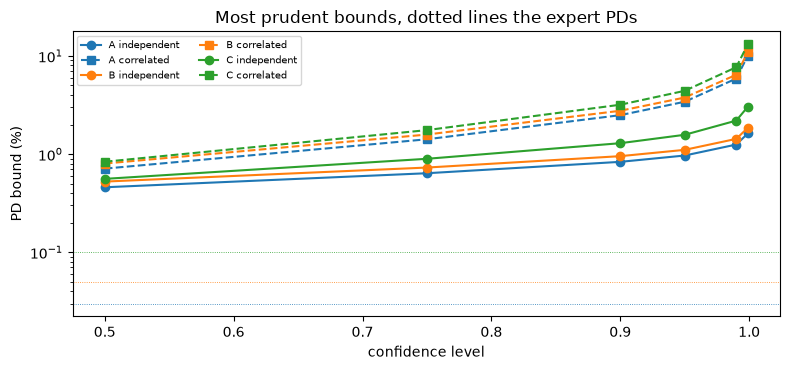

In [10]:
# Draw the bounds against the confidence level, independent and correlated, with the expert PDs
fig, ax = plt.subplots(figsize=(8, 3.8))
for j, color in enumerate(("tab:blue", "tab:orange", "tab:green")):
    ax.plot(gammas, 100 * independent[:, j], color=color, marker="o", label=f"{grades[j]} independent")
    ax.plot(gammas, 100 * correlated[:, j], color=color, marker="s", linestyle="--", label=f"{grades[j]} correlated")
    ax.axhline(100 * out["expert_pd"][j], color=color, linewidth=0.6, linestyle=":")
ax.set_yscale("log")
ax.set_xlabel("confidence level")
ax.set_ylabel("PD bound (%)")
ax.set_title("Most prudent bounds, dotted lines the expert PDs")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

## Results

- **The bound for each grade rests on the pool.** Pooled from each grade down to the worst, the counts are 800, 700 and 300 obligors with 3, 3 and 1 defaults; the 90% bounds are 0.833%, 0.952% and 1.290%. They equal SciPy's Beta quantile and the committed bounds at six levels, and with no default the engine equals the closed form 1 - (1 - gamma)^(1/N) (0.287%, 0.328% and 0.765% at 90%).
- **Correlation widens the bound.** With the paper's asset correlation of 12% the 90% bounds are 2.49%, 2.76% and 3.18%, about three times the independent ones for A and B and 2.5 times for C; at 99.9% grade A's bound is 10.08%, 6.2 times its independent bound.
- **Scaling.** Scaled to the best grade's bound (the paper's proposal) the 90% bounds become 0.652%, 0.745% and 1.010% (K = 0.783); scaled to the portfolio's observed default rate of 0.375% they become 0.294%, 0.336% and 0.455% (K = 0.352). In both cases the weighted average equals the target and the order is kept.
- **Years of observation.** The five-year bounds with 12% asset correlation and 30% year-to-year factor correlation are lower than the one-year ones: at 90%, 0.324%, 0.365% and 0.443% against 0.833%, 0.952% and 1.290% for the example, and 0.105%, 0.119% and 0.255% against 0.287%, 0.328% and 0.765% with no default.
- **The 204 printed cells.** The engine reproduces 129 to the printed digit. Sixty differ by one unit of the last printed digit and 15 by more (0.02 to 0.05 points in Tables 11, 13 and 14, and 0.10 in one cell of Table 12, B at 99.9%: printed 9.54, recomputed 9.44). Where they differ the print is above the recomputation in 68 of 75 cells; Table 4's 0.65% is the bound at 76.3% and not at 75% (0.638%); the multi-period prints are above the Monte Carlo value. The recomputation equals the committed comparison cell by cell.
- **What a known truth says.** In the zero-default generated year the independent bound of grade C covers the true PD in every one of 20,000 years at every level from 50% to 99%, with a median bound of 1.15 times the truth at 50% and 7.6 times at 99%. Grade B at 50% covers it in 45.4% of the years (standard error 0.35 points) and the scaled estimate of grade C at 50% in 46.5%, because 53.5% of the years have no default at all. The bounds are conservative by construction and the scaled ones give up coverage.
- **The expert and the capital.** The hypothetical expert's PDs are rejected by the Jeffreys test for grade B (p = 0.0047, red) and for the portfolio (p = 0.0062, red), amber by the binomial test (p = 0.0167) and green once correlation is allowed (p = 0.0507). Their average IRB risk weight is 23.4%, against 83.8% with the 75% bounds, 108.1% with the correlated ones and 77.2% with the scaled ones: the estimation principle is worth tens of points of risk weight.

What this notebook does not show: how a validator chooses a confidence level (the paper calls the choice arbitrary and says levels below 95% seem more appropriate), or the PD curve of a rated portfolio (notebooks 05 and 09).

## Summary

- With few or no defaults a grade's PD is an upper confidence bound on the pool of that grade and all worse ones; the bound is monotone across grades and positive even with no default.
- Default correlation raises the bound several times; scaling to a portfolio target lowers it and gives up its reading as a bound; several years of observation lower it.
- The 204 printed cells of the paper are recomputed: 129 to the digit, the rest reported with their gap and the reason the committed notes give.
- A bound is conservative by construction: on known truth it covers in every year and is several times the true PD.

**What to try next.** Change the number of defaults of grade A in Step 1 from 0 to 1 and watch the three bounds move; then read notebook 07.

## References

- Pluto, K. and Tasche, D. (2005), Estimating probabilities of default for low default portfolios, in Engelmann and Rauhmeier (eds), The Basel II Risk Parameters, Springer; arXiv cond-mat/0411699, sections 2 to 6, Tables 1 to 14. https://arxiv.org/abs/cond-mat/0411699
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2), for the Clopper-Pearson and Jeffreys bounds. https://doi.org/10.1214/ss/1009213286
- BCBS, Basel Framework, CRE32, IRB approach: risk-weighted asset calculation. https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162, for the one-factor model.